# Día 3 — ARIMA y SARIMA en Python

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 06-11-2026 · **Unidades 2 y 3** · Contenidos 2.4, 2.5 y 3.1 · **Actividad 2** (20 puntos, notebook aparte)

Ayer propusimos candidatos a partir de la ACF, la PACF y la prueba ADF:

| Evidencia (Día 2) | Decisión |
|---|---|
| la inflación es aproximadamente estacionaria | $d = 0$ (probar también $d = 1$) |
| la PACF se corta en el rezago 1 | $p = 1$ |
| bastones en el rezago 12 | término estacional $P = 1$, $s = 12$ |

Hoy los **estimamos**, aprendemos a **leer sus resultados**, revisamos sus **residuos**, construimos **intervalos de predicción** y los comparamos con la línea base de los Días 1 y 2.

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- cómo se crea, estima y consulta un modelo `ARIMA` en statsmodels;
- cómo leer la tabla de coeficientes de un ARIMA y qué significa cada parámetro;
- qué son el **AIC** y el **BIC** y para qué sirven;
- cómo saber si un modelo dejó información sin aprovechar, revisando sus **residuos** (prueba de Ljung-Box);
- qué es un **intervalo de predicción** y por qué se ensancha con el horizonte;
- por qué un modelo estadísticamente mejor **no siempre pronostica mejor**;
- qué son, conceptualmente, un **VAR** y la **cointegración**;
- cómo convertir una serie en una tabla de aprendizaje supervisado (puente al Día 4).

## Ruta del día

| Parte | Qué haremos | Herramienta |
|---|---|---|
| 1 | La clase `ARIMA` de statsmodels | `ARIMA`, `.fit()`, `.summary()` |
| 2 | Primer modelo: AR(1) como ARIMA(1, 0, 0) | — |
| 3 | Comparar candidatos con AIC y BIC | bucle |
| 4 | Diagnóstico de residuos | `plot_diagnostics`, `acorr_ljungbox` |
| 5 | Pronósticos e intervalos de predicción | `get_forecast`, `conf_int` |
| 6 | Validación a un paso y comparación con la línea base | `apply`, `predict` |
| 7 | Variable de intervención: el IVA de abril de 2024 | `exog` |
| 8 | VAR y cointegración (conceptual) | `coint` |
| 9 | Una serie como problema supervisado (3.1) | `shift`, `LinearRegression` |

# 0. Librerías

La herramienta central de hoy es `ARIMA`, del módulo `statsmodels.tsa.arima.model`. Sirve para todos los modelos del Día 2: AR, MA, ARMA, ARIMA y SARIMA, cambiando solo sus parámetros.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# statsmodels
from statsmodels.tsa.arima.model import ARIMA                  # modelos ARIMA y SARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox         # prueba de residuos
from statsmodels.tsa.stattools import adfuller, coint          # estacionariedad y cointegración
from statsmodels.graphics.tsaplots import plot_acf

# scikit-learn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')   # statsmodels avisa de convergencia en algunos candidatos

`warnings.filterwarnings('ignore')` oculta avisos de optimización que statsmodels muestra al probar varios modelos. En un trabajo real conviene leerlos; aquí los ocultamos para que el notebook se lea con claridad.

In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('datos') if Path('datos').exists() else Path('../datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


In [3]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series['ipc_var_mensual'].loc['2005':].dropna()

print(f'{len(y)} meses, de {y.index.min():%b %Y} a {y.index.max():%b %Y} · frecuencia {y.index.freqstr}')

260 meses, de Jan 2005 a Aug 2026 · frecuencia MS


**Qué obtuvimos:** la misma serie de los días anteriores, con frecuencia mensual explícita (`MS`). ARIMA necesita conocer la frecuencia para fechar correctamente los pronósticos.

Usaremos tres periodos, como el Día 2:

| Periodo | Uso hoy |
|---|---|
| 2005–2014 | estimar los parámetros para la validación |
| 2015–2024 | validar a un paso (120 meses) |
| 2025–ago 2026 | **Test**: comprobar una sola vez |

# 1. La clase `ARIMA` de statsmodels

`ARIMA` sigue el patrón de statsmodels: **crear → `fit()` → consultar**.

## 1.1 Crear el modelo: sus parámetros

| Parámetro | Qué indica | Ejemplo |
|---|---|---|
| `endog` | la serie que queremos pronosticar | `y` |
| `order` | la tupla $(p, d, q)$ | `(1, 0, 0)` |
| `seasonal_order` | la tupla $(P, D, Q, s)$ | `(1, 0, 0, 12)` |
| `trend` | términos deterministas: `'c'` constante, `'n'` ninguno | `'c'` si $d = 0$ |
| `exog` | variables explicativas externas (opcional) | una variable de intervención |

**Sobre `trend`:** si $d = 0$, la serie oscila alrededor de una media y necesitamos la constante (`'c'`). Si $d = 1$, la diferencia elimina el nivel y normalmente no se incluye (`'n'`).

## 1.2 Estimar: `fit()`

`fit()` busca los parámetros que hacen **más probable** la serie observada (estimación por **máxima verosimilitud**). Para un AR(1) el resultado se parece mucho a la regresión del Día 2; para modelos con MA no hay fórmula cerrada y statsmodels usa un algoritmo de optimización.

## 1.3 Consultar el resultado

`fit()` devuelve un objeto de resultados con:

| Atributo o método | Contenido |
|---|---|
| `.params` | los parámetros estimados |
| `.summary()` | tabla completa: coeficientes, errores estándar, p-valores, AIC, pruebas |
| `.aic`, `.bic` | criterios de información (parte 3) |
| `.resid` | residuos: real menos ajustado |
| `.plot_diagnostics()` | cuatro gráficos para revisar los residuos |
| `.get_forecast(steps)` | pronóstico con intervalos |
| `.apply(nueva_serie)` | aplicar los mismos parámetros a otra serie (parte 6) |

# 2. Primer modelo: ARIMA(1, 0, 0)

Empezamos por el candidato más simple: un AR(1) con constante. Lo estimamos con los datos hasta diciembre de 2024 (todo menos el Test).

**Qué vamos a hacer:** los tres pasos, uno por línea.

In [4]:
train = y.loc[:'2024-12']

modelo = ARIMA(train, order=(1, 0, 0), trend='c')   # 1. crear
resultado = modelo.fit()                            # 2. estimar

print(resultado.params.round(4))                    # 3. consultar

const     0.2128
ar.L1     0.4230
sigma2    0.1116
dtype: float64


**Qué obtuvimos:** tres parámetros.

| Parámetro | Valor | Significado |
|---|---:|---|
| `const` | ≈ 0.21 | **la media del proceso** (en `ARIMA` de statsmodels, la constante es la media, no la $c$ del Día 2) |
| `ar.L1` | ≈ 0.42 | $\phi$: cuánto se transmite del mes anterior |
| `sigma2` | ≈ 0.11 | varianza de los choques $\varepsilon_t$ |

> **Diferencia con `AutoReg` del Día 2:** allí la constante era $c \approx 0.12$ y la media se calculaba como $c/(1-\phi) \approx 0.22$. `ARIMA` estima directamente la media. Son dos formas de escribir el mismo modelo:
> $$y_t - \mu = \phi\,(y_{t-1} - \mu) + \varepsilon_t \quad\Longleftrightarrow\quad y_t = \underbrace{\mu(1-\phi)}_{c} + \phi\, y_{t-1} + \varepsilon_t$$

$\sqrt{\sigma^2} \approx 0.33$: el choque típico de un mes es de un tercio de punto porcentual, mayor que la propia media. Esto anticipa intervalos de predicción anchos.

## 2.1 El resumen completo: `summary()`

In [5]:
print(resultado.summary())

                               SARIMAX Results                                
Dep. Variable:        ipc_var_mensual   No. Observations:                  240
Model:                 ARIMA(1, 0, 0)   Log Likelihood                 -77.469
Date:                Mon, 02 Nov 2026   AIC                            160.938
Time:                        12:19:33   BIC                            171.380
Sample:                    01-01-2005   HQIC                           165.145
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2128      0.038      5.593      0.000       0.138       0.287
ar.L1          0.4230      0.043      9.952      0.000       0.340       0.506
sigma2         0.1116      0.008     13.978      0.0

### Cómo leer el resumen, bloque por bloque

**Bloque superior (información del modelo):**

| Campo | Lectura |
|---|---|
| `Dep. Variable` | la serie modelada |
| `No. Observations` | 240 meses (2005–2024) |
| `Model` | `ARIMA(1, 0, 0)` |
| `Log Likelihood` | qué tan probable es la serie según el modelo (más alto = mejor ajuste) |
| `AIC`, `BIC` | criterios para comparar modelos (más bajo = mejor; parte 3) |

**Bloque central (coeficientes):** se lee igual que en el Día 2: `coef`, `std err`, `z`, `P>|z|` e intervalo al 95 %. Los dos coeficientes tienen p-valor ≈ 0: ambos son significativos.

**Bloque inferior (pruebas sobre los residuos):**

| Prueba | Pregunta | Qué queremos |
|---|---|---|
| `Ljung-Box (L1) (Q)` y `Prob(Q)` | ¿los residuos tienen autocorrelación? | p-valor **alto** (> 0.05): residuos sin patrón |
| `Jarque-Bera (JB)` y `Prob(JB)` | ¿los residuos son normales? | p-valor alto; si es bajo, hay atípicos o colas pesadas |
| `Heteroskedasticity (H)` | ¿la varianza de los residuos cambia en el tiempo? | p-valor alto |

En este modelo:

- **Ljung-Box (L1)** tiene p-valor ≈ 0.74: no hay autocorrelación en el **rezago 1**. Pero esta prueba solo mira un rezago; en la parte 4 veremos que en el **rezago 12** sí queda autocorrelación.
- **Jarque-Bera** tiene p-valor ≈ 0: los residuos **no son normales** (curtosis ≈ 4.4, mayor que el 3 de una normal). Ya sabemos por qué: los atípicos de 2024 (Día 1). Esto afecta la precisión de los intervalos de predicción.

# 3. Comparar candidatos: AIC y BIC

## 3.1 ¿Qué son?

Un modelo con más parámetros **siempre** ajusta igual o mejor los datos de entrenamiento, pero puede sobreajustar (Módulo 3). Los **criterios de información** premian el ajuste y castigan la complejidad:

$$
AIC = -2\,\log L + 2k \qquad\qquad BIC = -2\,\log L + k\,\log n
$$

| Símbolo | Significado |
|---|---|
| $\log L$ | log-verosimilitud: qué tan bien ajusta |
| $k$ | número de parámetros |
| $n$ | número de observaciones |

- **Más bajo es mejor.**
- El BIC castiga más los parámetros (porque $\log n > 2$ cuando $n > 7$): tiende a elegir modelos más simples.
- **Solo se comparan modelos estimados con los mismos datos.** Un modelo con $d = 1$ pierde una observación; por eso su AIC no es directamente comparable con uno de $d = 0$.

### A mano

Para el ARIMA(1, 0, 0) que acabamos de estimar, el resumen muestra $\log L = -77.47$, con $k = 3$ parámetros y $n = 240$:

$$
AIC = -2(-77.47) + 2(3) = 154.94 + 6 = 160.94
$$

$$
BIC = 154.94 + 3\log(240) = 154.94 + 3(5.48) = 171.38
$$

In [6]:
k = len(resultado.params)
print('log L =', round(resultado.llf, 2), '· k =', k, '· n =', int(resultado.nobs))
print('AIC a mano:', round(-2 * resultado.llf + 2 * k, 2), '· statsmodels:', round(resultado.aic, 2))
print('BIC a mano:', round(-2 * resultado.llf + k * np.log(resultado.nobs), 2), '· statsmodels:', round(resultado.bic, 2))

log L = -77.47 · k = 3 · n = 240
AIC a mano: 160.94 · statsmodels: 160.94
BIC a mano: 171.38 · statsmodels: 171.38


**Qué obtuvimos:** el cálculo a mano coincide con `resultado.aic` y `resultado.bic`.

## 3.2 Probar varios candidatos

**Qué vamos a hacer:** estimar ocho modelos con los datos hasta 2024 y ordenar por AIC. Guardamos también el p-valor de la prueba de Ljung-Box sobre los residuos (parte 4) para usarlo después.

In [7]:
candidatos = {
    'ARIMA(1,0,0)':            ((1, 0, 0), (0, 0, 0, 0)),
    'ARIMA(2,0,0)':            ((2, 0, 0), (0, 0, 0, 0)),
    'ARIMA(1,0,1)':            ((1, 0, 1), (0, 0, 0, 0)),
    'ARIMA(0,1,1)':            ((0, 1, 1), (0, 0, 0, 0)),
    'ARIMA(1,1,1)':            ((1, 1, 1), (0, 0, 0, 0)),
    'SARIMA(1,0,0)(1,0,0)12':  ((1, 0, 0), (1, 0, 0, 12)),
    'SARIMA(1,0,1)(1,0,0)12':  ((1, 0, 1), (1, 0, 0, 12)),
    'SARIMA(1,0,0)(2,0,0)12':  ((1, 0, 0), (2, 0, 0, 12)),
}

def estimar(serie, order, seasonal_order, exog=None):
    """Estima un ARIMA/SARIMA con constante si d = 0."""
    tendencia = 'c' if order[1] == 0 else 'n'
    return ARIMA(serie, order=order, seasonal_order=seasonal_order, trend=tendencia, exog=exog).fit()

filas = []
ajustados = {}
for nombre, (order, seasonal_order) in candidatos.items():
    r = estimar(train, order, seasonal_order)
    ajustados[nombre] = r
    filas.append({
        'modelo': nombre,
        'parametros': len(r.params),
        'AIC': r.aic,
        'BIC': r.bic,
        'LjungBox_p_12': acorr_ljungbox(r.resid, lags=[12])['lb_pvalue'].iloc[0],
    })

tabla_modelos = pd.DataFrame(filas).set_index('modelo').sort_values('AIC')
tabla_modelos.round(3)

,parametros,AIC,BIC,LjungBox_p_12
modelo,,,,
"SARIMA(1,0,0)(2,0,0)12",5,138.846,156.249,0.426
"SARIMA(1,0,0)(1,0,0)12",4,139.671,153.593,0.484
"SARIMA(1,0,1)(1,0,0)12",5,140.474,157.877,0.599
"ARIMA(1,1,1)",3,156.472,166.901,0.016
"ARIMA(1,0,0)",3,160.938,171.380,0.000
"ARIMA(1,0,1)",4,161.545,175.468,0.001
"ARIMA(2,0,0)",4,162.216,176.139,0.001
"ARIMA(0,1,1)",2,173.335,180.288,0.000


### Qué nos dice la tabla

- **Los tres SARIMA tienen el AIC más bajo** (≈ 139–140) frente a los ARIMA sin parte estacional con $d = 0$ (≈ 161–162). Agregar el rezago 12 mejora el ajuste de forma clara, como anticipaba la PACF.
- El **BIC** prefiere el **SARIMA(1,0,0)(1,0,0)₁₂**, el más simple de los estacionales.
- Los modelos con $d = 1$ no se deben comparar por AIC con los de $d = 0$ (ver 3.1); los evaluaremos con pronósticos en la parte 6.
- La última columna anticipa la parte 4: **solo los SARIMA tienen residuos sin autocorrelación** (p-valor > 0.05).

Elegimos como modelo principal el **SARIMA(1,0,0)(1,0,0)₁₂**: mejor BIC, residuos limpios y pocos parámetros.

In [8]:
sarima = ajustados['SARIMA(1,0,0)(1,0,0)12']
print(sarima.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2085      0.053      3.900      0.000       0.104       0.313
ar.L1          0.4064      0.040     10.104      0.000       0.328       0.485
ar.S.L12       0.3387      0.076      4.472      0.000       0.190       0.487
sigma2         0.1006      0.007     14.735      0.000       0.087       0.114


### Interpretación de los coeficientes del SARIMA

$$
(y_t - \mu) = \phi\,(y_{t-1} - \mu) + \Phi\,(y_{t-12} - \mu) + \dots + \varepsilon_t
$$

| Parámetro | Valor | Lectura económica |
|---|---:|---|
| `const` ($\mu$) | ≈ 0.21 | inflación mensual media |
| `ar.L1` ($\phi$) | ≈ 0.41 | 41 % de la desviación del mes pasado se mantiene (en el AR(1) era 0.42) |
| `ar.S.L12` ($\Phi$) | ≈ 0.34 | 34 % de la desviación del **mismo mes del año pasado** se repite |
| `sigma2` | ≈ 0.10 | varianza del choque: menor que en el AR(1) (≈ 0.11) |

El SARIMA combina las dos ideas del Día 1: el ingenuo ("como el mes pasado") y el ingenuo estacional ("como el mismo mes del año pasado"), pero **ponderadas** y **atenuadas hacia la media**.

# 4. Diagnóstico de residuos (2.5)

## 4.1 ¿Por qué mirar los residuos?

El **residuo** de un modelo es lo que no logró explicar:

$$
e_t = y_t - \hat y_{t \mid t-1}
$$

Si el modelo aprovechó toda la información del pasado, los residuos deben parecer **ruido blanco**:

1. media cercana a cero;
2. **sin autocorrelación** (si quedara, el pasado todavía tendría información sin usar);
3. varianza estable;
4. idealmente, distribución normal (necesaria para que los intervalos sean exactos).

## 4.2 Los cuatro gráficos de `plot_diagnostics`

**Qué vamos a hacer:** comparar los diagnósticos del AR(1) y del SARIMA.

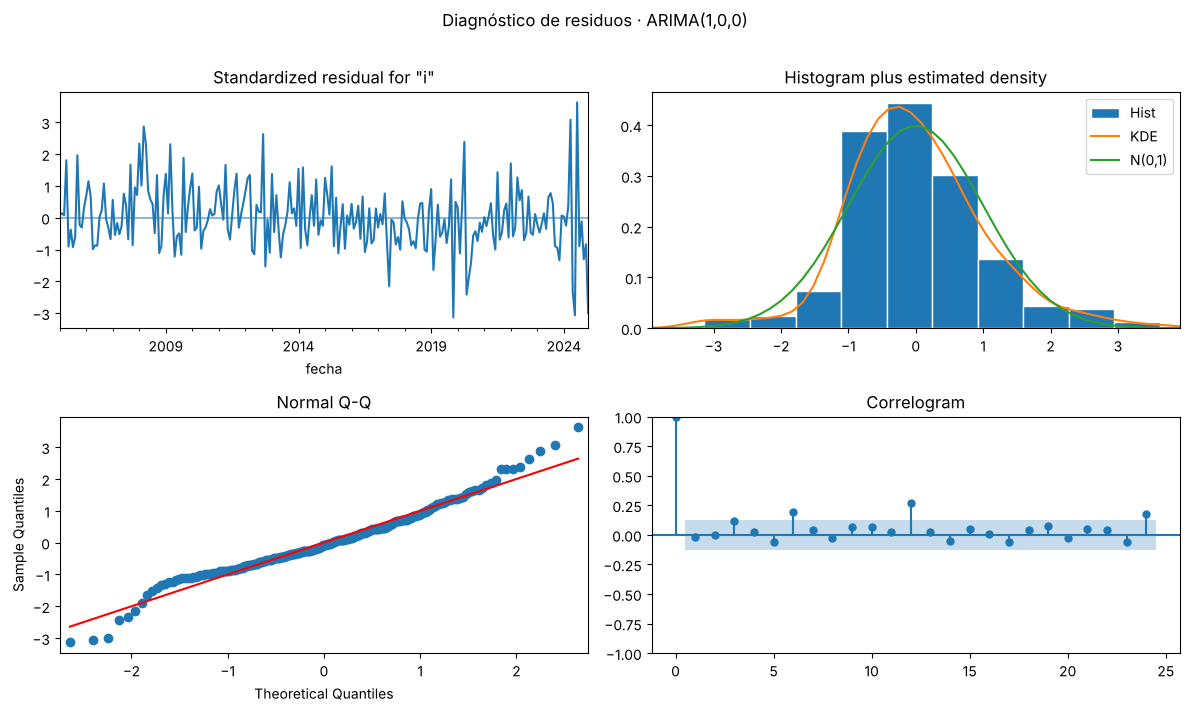

In [9]:
fig = ajustados['ARIMA(1,0,0)'].plot_diagnostics(figsize=(12, 7), lags=24)
fig.suptitle('Diagnóstico de residuos · ARIMA(1,0,0)', y=1.01)
plt.tight_layout()
plt.show()

### Cómo leer cada panel

| Panel | Qué muestra | Lo que esperamos | Lo que vemos en el AR(1) |
|---|---|---|---|
| **Standardized residual** (arriba izq.) | residuos en el tiempo, en desviaciones estándar | ruido sin patrón alrededor de 0 | ruido, con picos en 2008 y 2024 |
| **Histogram + KDE** (arriba der.) | distribución de los residuos frente a la normal N(0,1) | parecida a la curva verde | colas más largas que la normal |
| **Normal Q-Q** (abajo izq.) | cuantiles de los residuos frente a una normal | puntos sobre la línea roja | se separan en los extremos: atípicos |
| **Correlogram** (abajo der.) | ACF de los residuos | todos dentro de la banda | **el rezago 12 sobresale** |

El correlograma es el diagnóstico clave: **al AR(1) le falta la estacionalidad**.

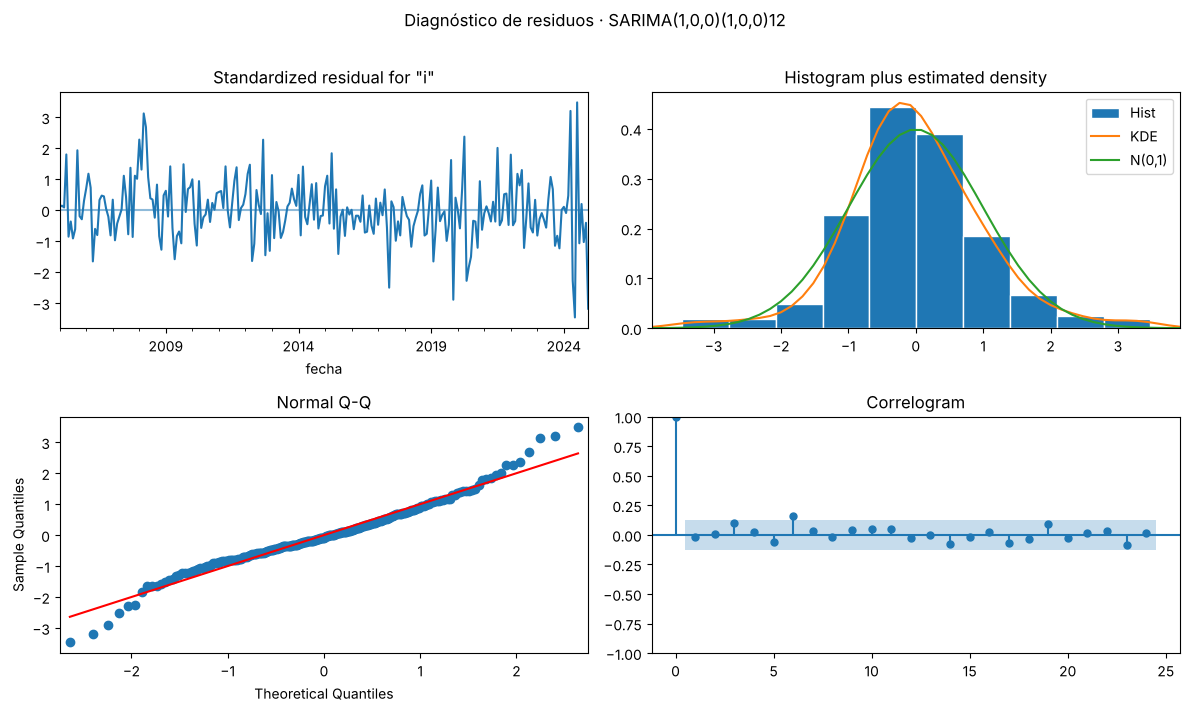

In [10]:
fig = sarima.plot_diagnostics(figsize=(12, 7), lags=24)
fig.suptitle('Diagnóstico de residuos · SARIMA(1,0,0)(1,0,0)12', y=1.01)
plt.tight_layout()
plt.show()

**Con el SARIMA, el rezago 12 del correlograma ya está dentro de la banda.** Los residuos siguen sin ser normales (los atípicos no desaparecen con ningún ARIMA), pero ya no tienen autocorrelación.

## 4.3 La prueba de Ljung-Box

La prueba de **Ljung-Box** resume el correlograma en un número: ¿las primeras $m$ autocorrelaciones de los residuos son, en conjunto, cero?

| | Enunciado |
|---|---|
| $H_0$ | los residuos no tienen autocorrelación (son ruido blanco) |
| $H_1$ | hay autocorrelación en al menos un rezago |

**Decisión:** queremos **no rechazar** $H_0$, es decir, un **p-valor alto** (> 0.05).

`acorr_ljungbox(residuos, lags=[m])` devuelve una tabla con el estadístico (`lb_stat`) y el p-valor (`lb_pvalue`).

In [11]:
pd.DataFrame({
    nombre: acorr_ljungbox(ajustados[nombre].resid, lags=[6, 12, 24])['lb_pvalue']
    for nombre in ['ARIMA(1,0,0)', 'SARIMA(1,0,0)(1,0,0)12']
}).rename_axis('rezagos').round(3)

,"ARIMA(1,0,0)","SARIMA(1,0,0)(1,0,0)12"
rezagos,,
6,0.036,0.155
12,0.000,0.484
24,0.001,0.714


**Lectura:**

- **AR(1):** p-valores ≈ 0 con 12 y 24 rezagos → los residuos **tienen** autocorrelación → el modelo es **insuficiente**.
- **SARIMA:** p-valores altos en todos los rezagos → residuos compatibles con ruido blanco → el modelo **aprovechó** la información del pasado.

**El SARIMA pasa el diagnóstico; el AR(1) no.**

# 5. Pronósticos e intervalos de predicción (2.5)

## 5.1 Pronóstico puntual e intervalo

Un **pronóstico puntual** es un solo número ("la inflación de septiembre será 0.12 %"). Un **intervalo de predicción** da un rango con una probabilidad: "con 95 % de probabilidad estará entre −0.53 % y 0.77 %".

Para un horizonte $h$:

$$
\hat y_{t+h} \pm z \times \hat\sigma_h
$$

- $z = 1.96$ para un intervalo del 95 % (1.28 para el 80 %);
- $\hat\sigma_h$ es la desviación del error de pronóstico a $h$ pasos, que **crece con $h$**: cada mes adicional suma la incertidumbre de un nuevo choque.

> **Intervalo de predicción ≠ intervalo de confianza.** El de confianza (Día 2) se refiere a un **parámetro** ($\phi$ está entre 0.36 y 0.59). El de predicción se refiere a un **valor futuro** de la serie, e incluye el choque $\varepsilon$ que nadie puede anticipar. Por eso es mucho más ancho.

## 5.2 `get_forecast`

| Método | Qué devuelve |
|---|---|
| `resultado.get_forecast(steps=h)` | un objeto de pronóstico para los próximos $h$ meses |
| `.predicted_mean` | los pronósticos puntuales |
| `.conf_int(alpha=0.05)` | los límites del intervalo del 95 % (`alpha = 1 − nivel`) |

**Qué vamos a hacer:** reestimar el SARIMA con **toda** la serie (hasta agosto de 2026) y pronosticar septiembre, octubre y noviembre de 2026.

In [12]:
sarima_total = estimar(y, (1, 0, 0), (1, 0, 0, 12))

pronostico = sarima_total.get_forecast(steps=3)

tabla_pronostico = pd.DataFrame({
    'pronostico': pronostico.predicted_mean,
    'inferior_95': pronostico.conf_int(alpha=0.05).iloc[:, 0],
    'superior_95': pronostico.conf_int(alpha=0.05).iloc[:, 1],
    'inferior_80': pronostico.conf_int(alpha=0.20).iloc[:, 0],
    'superior_80': pronostico.conf_int(alpha=0.20).iloc[:, 1],
})
tabla_pronostico.round(2)

,pronostico,inferior_95,superior_95,inferior_80,superior_80
2026-09-01,0.12,-0.53,0.77,-0.31,0.55
2026-10-01,0.21,-0.48,0.89,-0.24,0.66
2026-11-01,0.05,-0.64,0.74,-0.40,0.50


### Cómo leer la tabla

Para septiembre de 2026, el SARIMA pronostica ≈ 0.12 %. El intervalo del 95 % va de ≈ −0.53 % a ≈ 0.77 %: **incluye tanto deflación como una inflación alta**. El del 80 % es más estrecho (≈ −0.31 % a ≈ 0.55 %).

¿Por qué tan ancho? Porque $\hat\sigma \approx 0.32$: el choque típico de un mes es mayor que la inflación media. **Esto no es un defecto del modelo, es información:** la inflación mensual del Ecuador es muy difícil de anticipar mes a mes. Comunicarlo es parte del trabajo del analista.

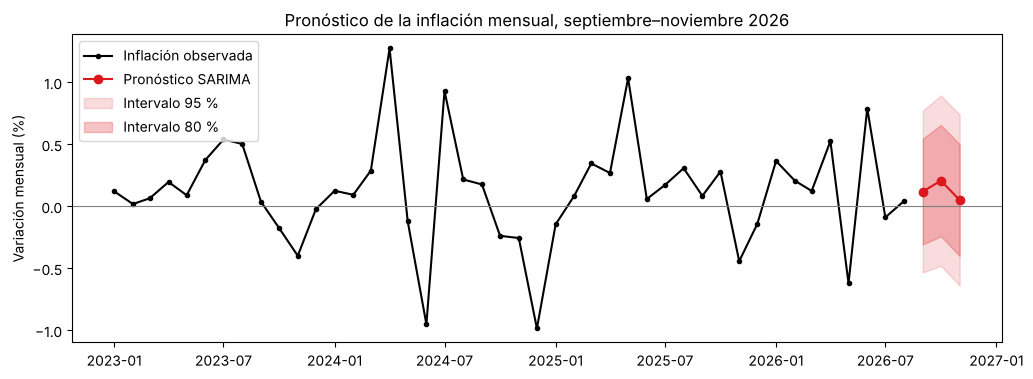

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.loc['2023':], color='black', marker='o', markersize=3, label='Inflación observada')
ax.plot(tabla_pronostico['pronostico'], color='#DA181E', marker='o', label='Pronóstico SARIMA')
ax.fill_between(tabla_pronostico.index, tabla_pronostico['inferior_95'], tabla_pronostico['superior_95'],
                color='#DA181E', alpha=0.15, label='Intervalo 95 %')
ax.fill_between(tabla_pronostico.index, tabla_pronostico['inferior_80'], tabla_pronostico['superior_80'],
                color='#DA181E', alpha=0.25, label='Intervalo 80 %')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Variación mensual (%)')
ax.set_title('Pronóstico de la inflación mensual, septiembre–noviembre 2026')
ax.legend(loc='upper left')
plt.show()

### El intervalo se ensancha con el horizonte

**Qué vamos a hacer:** pronosticar 24 meses y medir el ancho del intervalo del 95 % en cada horizonte.

In [14]:
largo = sarima_total.get_forecast(steps=24)
ancho = largo.conf_int(alpha=0.05).diff(axis=1).iloc[:, 1]

print('Ancho del intervalo 95 % por horizonte:')
print(pd.Series(ancho.values, index=range(1, 25)).loc[[1, 2, 3, 6, 12, 24]].round(3).to_string())
print('\nPronóstico a 24 meses:', round(largo.predicted_mean.iloc[-1], 3), '· media estimada:', round(sarima_total.params['const'], 3))

Ancho del intervalo 95 % por horizonte:
1     1.306
2     1.373
3     1.380
6     1.381
12    1.381
24    1.419

Pronóstico a 24 meses: 0.201 · media estimada: 0.211


**Lectura:** el ancho pasa de ≈ 1.31 puntos en $h = 1$ a ≈ 1.38 desde $h = 3$, y apenas sube hasta ≈ 1.42 en $h = 24$: en un modelo estacionario la incertidumbre crece **hasta un límite**, porque el pronóstico de largo plazo converge a la media. En una serie no estacionaria (por ejemplo, el IPC en nivel), el intervalo crecería sin límite.

# 6. Validación a un paso y comparación con la línea base

## 6.1 Estrategia

El AIC nos dice qué modelo **ajusta** mejor el pasado. La pregunta del módulo es otra: **¿cuál pronostica mejor?** Lo medimos con pronósticos a un paso fuera de la muestra.

Estimar un ARIMA 120 veces (una por pliegue) sería lento. statsmodels ofrece un atajo:

1. **Estimar** los parámetros con 2005–2014.
2. **Aplicar** esos mismos parámetros a la serie 2005–2024 con `.apply()`: el modelo no se reestima, solo se filtra la serie con los parámetros fijos.
3. **Predecir** con `.predict(start, end)`: para cada mes, statsmodels usa la información **hasta el mes anterior**. Es un pronóstico a un paso con parámetros fijos.

Es una validación ligeramente más exigente que el origen móvil completo (los parámetros no se actualizan), pero honesta: **ningún dato de validación se usó para estimar**.

In [15]:
inicio_val, fin_val = '2015-01-01', '2024-12-01'

def errores_un_paso(order, seasonal_order, hasta_estimacion, serie_completa, inicio, fin):
    """Errores a un paso: parámetros estimados hasta `hasta_estimacion`, aplicados a la serie completa."""
    r = estimar(serie_completa.loc[:hasta_estimacion], order, seasonal_order)
    r_aplicado = r.apply(serie_completa)                     # mismos parámetros, más datos
    pred = r_aplicado.predict(start=inicio, end=fin)          # a un paso, sin mirar el mes pronosticado
    return serie_completa.loc[inicio:fin] - pred

hasta_2024 = y.loc[:'2024-12']
errores_val = {
    nombre: errores_un_paso(o, so, '2014-12', hasta_2024, inicio_val, fin_val)
    for nombre, (o, so) in candidatos.items()
}

# Línea base del Día 2: promedio móvil de 12 meses, a un paso.
pm12 = y.rolling(12).mean().shift(1)
errores_val['Línea base: promedio móvil 12'] = (y - pm12).loc[inicio_val:fin_val]

errores_val = pd.DataFrame(errores_val)
print('Meses validados:', len(errores_val))

Meses validados: 120


In [16]:
validacion = pd.DataFrame({
    'MAE_2015_2023': errores_val.loc[:'2023'].abs().mean(),
    'MAE_2024': errores_val.loc['2024'].abs().mean(),
    'RMSE_2015_2023': np.sqrt((errores_val.loc[:'2023'] ** 2).mean()),
})
validacion.sort_values('MAE_2015_2023').round(3)

,MAE_2015_2023,MAE_2024,RMSE_2015_2023
Línea base: promedio móvil 12,0.223,0.472,0.286
"SARIMA(1,0,0)(2,0,0)12",0.226,0.527,0.294
"SARIMA(1,0,1)(1,0,0)12",0.228,0.526,0.297
"SARIMA(1,0,0)(1,0,0)12",0.229,0.533,0.299
"ARIMA(1,1,1)",0.233,0.536,0.299
"ARIMA(0,1,1)",0.236,0.559,0.301
"ARIMA(2,0,0)",0.242,0.558,0.309
"ARIMA(1,0,1)",0.243,0.559,0.310
"ARIMA(1,0,0)",0.245,0.562,0.312


### Qué nos dice la validación

- **Los SARIMA son los mejores modelos ARIMA** en 2015–2023 (MAE ≈ 0.23), coherente con el AIC y el diagnóstico.
- **Pero la línea base (promedio móvil de 12) es tan buena o mejor** (≈ 0.22). La diferencia es de centésimas.
- En 2024 todos los modelos tienen errores mucho mayores (≈ 0.53–0.56): los choques de ese año no los anticipa nadie.

## 6.2 Test: una sola vez

Fijamos los modelos y medimos en enero 2025 – agosto 2026. Ahora los parámetros se estiman con **todo hasta 2024**.

In [17]:
inicio_test, fin_test = '2025-01-01', '2026-08-01'

errores_test = {
    nombre: errores_un_paso(o, so, '2024-12', y, inicio_test, fin_test)
    for nombre, (o, so) in candidatos.items()
}
errores_test['Línea base: promedio móvil 12'] = (y - pm12).loc[inicio_test:fin_test]
errores_test = pd.DataFrame(errores_test)

test = pd.DataFrame({
    'MAE_Test': errores_test.abs().mean(),
    'RMSE_Test': np.sqrt((errores_test ** 2).mean()),
    'Bias_Test': -errores_test.mean(),   # pronóstico − real
})
test.sort_values('MAE_Test').round(3)

,MAE_Test,RMSE_Test,Bias_Test
Línea base: promedio móvil 12,0.286,0.405,-0.066
"ARIMA(0,1,1)",0.307,0.416,-0.071
"ARIMA(1,0,0)",0.307,0.436,0.007
"ARIMA(1,1,1)",0.308,0.429,-0.050
"ARIMA(2,0,0)",0.308,0.427,0.003
"ARIMA(1,0,1)",0.309,0.422,-0.003
"SARIMA(1,0,1)(1,0,0)12",0.365,0.493,-0.012
"SARIMA(1,0,0)(2,0,0)12",0.367,0.506,-0.009
"SARIMA(1,0,0)(1,0,0)12",0.374,0.509,-0.006


### La lección del día: un mejor modelo estadístico no siempre pronostica mejor

| Criterio | Ganador |
|---|---|
| AIC / BIC (ajuste en 2005–2024) | SARIMA |
| Residuos (Ljung-Box) | SARIMA |
| Validación 2015–2023 | SARIMA ≈ línea base |
| **Test 2025–2026** | **línea base y ARIMA sin parte estacional** |

En el Test, los SARIMA quedan detrás: su término estacional **copia parte de los choques de 2024** en los mismos meses de 2025, el mismo problema que tuvo el ingenuo estacional el Día 1.

**¿Entonces el SARIMA no sirve?** Sí sirve, por razones que un pronóstico simple no ofrece:

1. **Intervalos de predicción** con fundamento estadístico.
2. **Interpretación** de la dinámica: persistencia mensual (≈ 0.41) y anual (≈ 0.34).
3. **Diagnóstico**: sabemos que no dejó información sin usar.
4. Se puede **extender** con variables externas (parte 7) y combinar con Machine Learning (Día 5).

Pero si el único objetivo fuera el MAE de 2025–2026, el promedio móvil sería difícil de superar. **Reconocer que un modelo complejo no mejora a uno simple es un resultado válido**, no un fracaso.

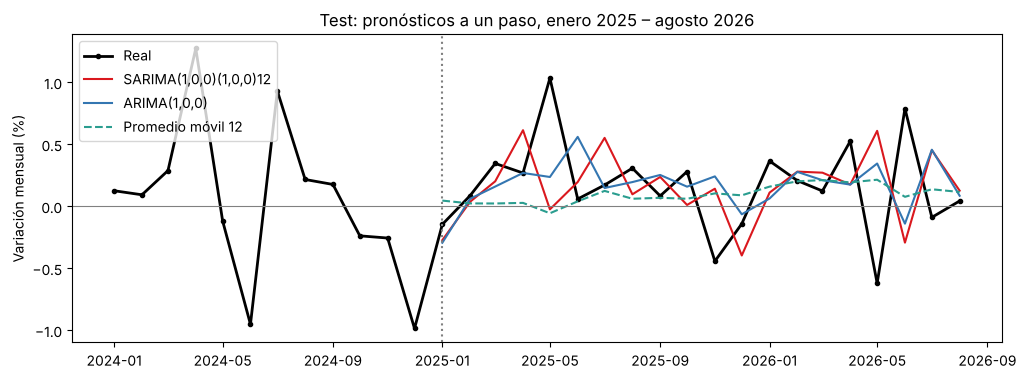

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.loc['2024':], color='black', marker='o', markersize=3, linewidth=2, label='Real')
for nombre, color in [('SARIMA(1,0,0)(1,0,0)12', '#DA181E'), ('ARIMA(1,0,0)', '#3476B1')]:
    pred = y.loc[inicio_test:fin_test] - errores_test[nombre]
    ax.plot(pred, label=nombre, color=color)
ax.plot(pm12.loc[inicio_test:fin_test], label='Promedio móvil 12', color='#2A9D8F', linestyle='--')
ax.axvline(pd.Timestamp('2025-01-01'), color='gray', linestyle=':')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_title('Test: pronósticos a un paso, enero 2025 – agosto 2026')
ax.set_ylabel('Variación mensual (%)')
ax.legend()
plt.show()

# 7. Variable de intervención: el IVA de abril de 2024

El Día 1 vimos que abril de 2024 tuvo un residuo de 0.90 puntos por el aumento del IVA del 12 % al 15 %. En la tabla de opciones para atípicos, la número 5 era **marcarlo con una variable**. Ahora podemos hacerlo.

## 7.1 La idea

Una **variable de intervención** (o *dummy*) vale 1 en el mes del evento y 0 en los demás. Se agrega al modelo como **variable externa** (`exog`):

$$
y_t = \mu + \beta\, D_t + \text{(parte ARIMA)} + \varepsilon_t
$$

El coeficiente $\beta$ estima el **efecto del evento**, y el resto del modelo ya no tiene que "explicar" ese mes con sus rezagos.

**Qué vamos a hacer:** crear la variable, estimar el SARIMA con y sin ella, y comparar.

In [19]:
iva_2024 = pd.Series(0.0, index=y.index, name='iva_abril_2024')
iva_2024.loc['2024-04-01'] = 1.0

print('Meses con valor 1:', iva_2024[iva_2024 == 1].index.strftime('%b %Y').tolist())

sarima_sin = estimar(train, (1, 0, 0), (1, 0, 0, 12))
sarima_con = estimar(train, (1, 0, 0), (1, 0, 0, 12), exog=iva_2024.loc[:'2024-12'])

print(sarima_con.summary().tables[1])

Meses con valor 1: ['Apr 2024']
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.2013      0.053      3.767      0.000       0.097       0.306
iva_abril_2024     1.1283      0.598      1.888      0.059      -0.043       2.300
ar.L1              0.4311      0.039     10.978      0.000       0.354       0.508
ar.S.L12           0.3342      0.071      4.701      0.000       0.195       0.473
sigma2             0.0944      0.006     14.803      0.000       0.082       0.107


### Lectura

- El coeficiente `iva_abril_2024` es ≈ 1.1: el modelo atribuye al IVA alrededor de **un punto porcentual** de inflación en abril de 2024, por encima de lo que explicaban la media, el mes anterior y abril de 2023.
- Su p-valor es ≈ 0.06, **en el límite** del 5 %, y su intervalo va de ≈ −0.04 a ≈ 2.3. Es lógico: el efecto se estima con **un solo mes**, así que es impreciso. La dirección y el tamaño son coherentes con el hecho económico.
- Los demás coeficientes cambian poco: el evento ya no "contamina" la estimación de la persistencia.

In [20]:
pd.DataFrame({
    'AIC': [sarima_sin.aic, sarima_con.aic],
    'sigma2': [sarima_sin.params['sigma2'], sarima_con.params['sigma2']],
}, index=['SARIMA sin intervención', 'SARIMA con intervención']).round(3)

,AIC,sigma2
SARIMA sin intervención,139.671,0.101
SARIMA con intervención,126.382,0.094


El AIC baja ≈ 13 puntos y la varianza del choque disminuye: **marcar el evento mejora el modelo**.

**Advertencias:**

- Una intervención se justifica con un **hecho económico documentado**, no con "este mes tuvo un residuo grande".
- Para **pronosticar** con `exog`, hay que dar valores futuros de la variable (`get_forecast(steps=3, exog=...)`). Para un evento pasado son ceros; para un evento futuro conocido (por ejemplo, un cambio de impuesto ya anunciado) se puede usar como **escenario** (Día 6).

# 8. VAR y cointegración (2.5, conceptual)

Hasta ahora cada modelo usa **una sola serie**. En economía las variables se influyen entre sí: el precio del petróleo afecta el riesgo país, las tasas afectan el crédito. Dos ideas permiten modelar eso. Hoy las vemos de forma conceptual.

## 8.1 Modelo VAR (vector autorregresivo)

Un **VAR** es un AR con **varias series a la vez**: cada variable depende de sus propios rezagos **y** de los rezagos de las otras. Con dos variables, inflación ($\pi$) y precio del petróleo ($p$):

$$
\begin{aligned}
\pi_t &= c_1 + a_{11}\,\pi_{t-1} + a_{12}\,p_{t-1} + \varepsilon_{1t} \\
p_t &= c_2 + a_{21}\,\pi_{t-1} + a_{22}\,p_{t-1} + \varepsilon_{2t}
\end{aligned}
$$

| Coeficiente | Pregunta que responde |
|---|---|
| $a_{11}$ | ¿la inflación depende de su propio pasado? (como en el AR) |
| $a_{12}$ | ¿el petróleo del mes pasado ayuda a pronosticar la inflación? |
| $a_{21}$ | ¿la inflación pasada ayuda a pronosticar el petróleo? |

**Para qué sirve:** pronosticar varias variables de forma conjunta y estudiar cómo un choque en una se transmite a las otras (**funciones impulso-respuesta**). Es una herramienta habitual en bancos centrales.

**Requisitos y límites:**

- todas las series deben ser **estacionarias** (o cointegradas, ver abajo);
- el número de parámetros crece rápido: con 5 variables y 2 rezagos son 55 coeficientes;
- en statsmodels: `from statsmodels.tsa.api import VAR`.

## 8.2 Cointegración

El Día 2 vimos que una serie no estacionaria se diferencia. Pero a veces **dos series no estacionarias se mueven juntas** en el largo plazo: cada una sube y baja, pero la distancia entre ellas es estable. Se dice que están **cointegradas**.

**Ejemplo intuitivo:** una persona y su perro con correa. Cada uno camina sin rumbo fijo (no estacionarios), pero la distancia entre ellos nunca supera el largo de la correa (estacionaria).

**Por qué importa:** si dos series están cointegradas, diferenciarlas por separado **pierde** la información de esa relación de largo plazo. Existen modelos que la conservan (*VECM*, vector de corrección de errores).

**Cómo se prueba:** con la prueba de **Engle-Granger** (`coint` en statsmodels). $H_0$: **no** hay cointegración.

### Ilustración con exportaciones e importaciones

Exportaciones e importaciones crecen con la economía (no estacionarias). Si estuvieran cointegradas, su diferencia, la **balanza comercial**, sería estacionaria.

ADF exportaciones (p): 0.743
ADF importaciones (p): 0.734
ADF balanza (p):       0.238
Engle-Granger exportaciones–importaciones (p): 0.293


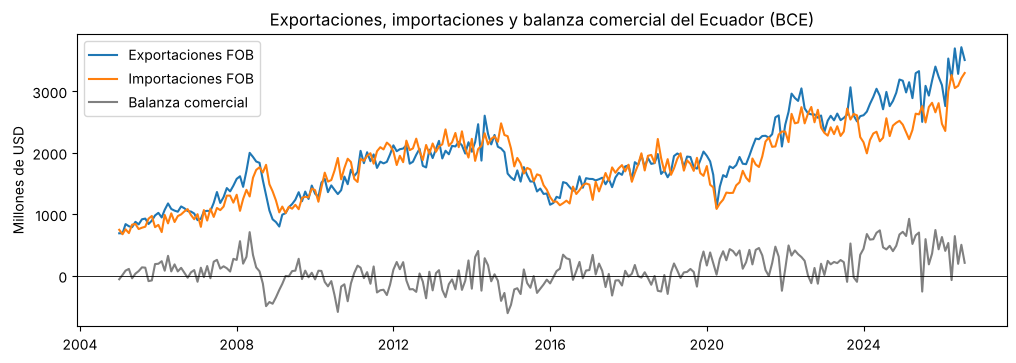

In [21]:
exportaciones = series['exportaciones_fob_musd'].loc['2005':'2026-08']
importaciones = series['importaciones_fob_musd'].loc['2005':'2026-08']
balanza = series['balanza_comercial_musd'].loc['2005':'2026-08']

print('ADF exportaciones (p):', round(adfuller(exportaciones, result_object=False)[1], 3))
print('ADF importaciones (p):', round(adfuller(importaciones, result_object=False)[1], 3))
print('ADF balanza (p):      ', round(adfuller(balanza, result_object=False)[1], 3))
print('Engle-Granger exportaciones–importaciones (p):', round(coint(exportaciones, importaciones)[1], 3))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(exportaciones, label='Exportaciones FOB')
ax.plot(importaciones, label='Importaciones FOB')
ax.plot(balanza, label='Balanza comercial', color='gray')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_ylabel('Millones de USD')
ax.set_title('Exportaciones, importaciones y balanza comercial del Ecuador (BCE)')
ax.legend()
plt.show()

### Lectura

- Exportaciones e importaciones **no son estacionarias** (p ≈ 0.74 y 0.73): crecen con el tiempo.
- La balanza tampoco pasa la prueba con claridad (p ≈ 0.24), y la prueba de Engle-Granger **no rechaza** la hipótesis de no cointegración (p ≈ 0.29).
- El gráfico muestra por qué: entre 2005 y 2026 la brecha entre ambas series cambió de forma persistente (déficits en 2009 y 2015, superávits más frecuentes desde 2020).

**Conclusión conceptual:** que dos series se parezcan en un gráfico no basta para afirmar una relación de largo plazo; hay que **probarla**. En este caso, la evidencia no la respalda en todo el periodo.

En este módulo no estimaremos VAR ni VECM; el Día 5 usaremos variables externas dentro de modelos de un solo objetivo.

# 9. Una serie como problema de aprendizaje supervisado (3.1)

## 9.1 La idea

En el Módulo 3, un modelo supervisado necesitaba una tabla con **columnas X** (predictores) y **una columna y** (objetivo). Una serie de tiempo es una sola columna. ¿Cómo usar Random Forest o regresión lineal?

**Construyendo la tabla con rezagos:** cada fila es un mes; el objetivo es la inflación de ese mes y los predictores son valores **anteriores**.

| Mes | $y_{t-12}$ | $y_{t-2}$ | $y_{t-1}$ | **$y_t$ (objetivo)** |
|---|---:|---:|---:|---:|
| ene 2025 | 0.13 | −0.26 | −0.99 | **−0.15** |
| feb 2025 | 0.09 | −0.99 | −0.15 | **0.09** |
| mar 2025 | 0.29 | −0.15 | 0.09 | **0.35** |

A esto se le llama **ventana deslizante** o **tabla de rezagos**. Mañana la usaremos con Random Forest.

**Qué vamos a hacer:** construirla con `shift` (Día 0) y quitar las filas incompletas.

In [22]:
tabla = pd.DataFrame({
    'rezago_12': y.shift(12),
    'rezago_2': y.shift(2),
    'rezago_1': y.shift(1),
    'objetivo': y,
}).dropna()

print('Filas de la tabla:', len(tabla), '(se pierden las 12 primeras por el rezago 12)')
tabla.loc['2025-01':'2025-03'].round(2)

Filas de la tabla: 248 (se pierden las 12 primeras por el rezago 12)


,rezago_12,rezago_2,rezago_1,objetivo
fecha,,,,
2025-01-01,0.13,-0.26,-0.99,-0.15
2025-02-01,0.09,-0.99,-0.15,0.09
2025-03-01,0.29,-0.15,0.09,0.35


**Qué obtuvimos:** 248 filas, y las de 2025 coinciden con la tabla de arriba.

## 9.2 Comprobación: una regresión lineal sobre el rezago 1 es un AR(1)

Si la tabla está bien construida, una `LinearRegression` del Módulo 3 con `rezago_1` como único predictor debe dar los mismos coeficientes que el AR(1) del Día 2 (estimado hasta 2023).

In [23]:
tabla_ar = pd.DataFrame({'rezago_1': y.shift(1), 'objetivo': y}).dropna().loc[:'2023-12']

regresion = LinearRegression().fit(tabla_ar[['rezago_1']], tabla_ar['objetivo'])

print('Intercepto (c):', round(regresion.intercept_, 4))
print('Coeficiente (phi):', round(regresion.coef_[0], 4))

Intercepto (c): 0.1173
Coeficiente (phi): 0.477


**Coinciden con el Día 2** ($c \approx 0.117$, $\phi \approx 0.477$). Un AR(1) **es** una regresión lineal sobre una tabla de rezagos.

Esta equivalencia es el puente al Día 4: si cambiamos `LinearRegression` por `RandomForestRegressor` y agregamos más columnas (más rezagos, el mes del año, promedios móviles), obtenemos un modelo de Machine Learning para series de tiempo.

### Cuidados que heredamos del Día 0

- **Solo rezagos positivos** como predictores (`shift(1)`, `shift(12)`); nunca `shift(-1)`.
- **No mezclar las filas al azar** para dividir Train y Test: el corte sigue siendo por fecha.
- Las primeras filas se pierden: con un rezago 12, el primer año desaparece.

# 10. Actividad 2 · Mi primer pronóstico ARIMA (20 puntos)

**Trabajo individual · 40 minutos.** Abre el notebook `Actividad2_ARIMA.ipynb` (en esta misma carpeta), ejecútalo completo, cambia el parámetro indicado y responde las cuatro preguntas dentro del archivo:

1. ¿Qué se pronosticó?
2. ¿Cómo cambió el resultado al modificar el parámetro?
3. ¿Qué muestran los errores?
4. ¿Qué limitaciones observas?

Puedes usar un agente de IA para entender o corregir el código; las respuestas deben basarse en los resultados de tu notebook.

# 11. Reto de cierre: riesgo país

Repite el procedimiento del día con `riesgo_pais_pb` desde 2005:

1. ¿Es estacionaria? Usa ADF y el gráfico de media móvil.
2. Propón dos candidatos (por ejemplo, ARIMA(1,0,0) y ARIMA(0,1,1)), estímalos y compara su AIC (solo si tienen el mismo $d$) y su diagnóstico de residuos.
3. Valida a un paso en 2015–2024 y compara con el pronóstico ingenuo (que el Día 1 ganó en esta serie).
4. Pronostica los próximos tres meses con intervalos del 80 % y del 95 %. ¿Qué tan anchos son en puntos básicos?
5. ¿Qué evento podrías marcar con una variable de intervención? Justifícalo con un hecho económico.

In [24]:
riesgo = series['riesgo_pais_pb'].loc['2005':].dropna()
print(f'{len(riesgo)} meses · último dato: {riesgo.index.max():%b %Y} = {riesgo.iloc[-1]:.0f} puntos básicos')

261 meses · último dato: Sep 2026 = 439 puntos básicos


In [25]:
# A partir de aquí escribe tus propias celdas.

## Checklist del día

- [ ] ¿Estimé el modelo solo con datos anteriores al periodo que voy a evaluar?
- [ ] ¿Sé leer `const`, `ar.L1`, `ar.S.L12` y `sigma2` del resumen?
- [ ] ¿Comparé candidatos con AIC/BIC **solo** cuando tenían el mismo $d$ y los mismos datos?
- [ ] ¿Revisé los residuos con `plot_diagnostics` y la prueba de Ljung-Box?
- [ ] ¿Presenté el pronóstico **con su intervalo** y expliqué su ancho?
- [ ] ¿Comparé contra la línea base y acepté el resultado aunque el modelo simple ganara?
- [ ] ¿Usé variables de intervención solo para hechos documentados?

**Puente hacia el Día 4:** ya tenemos una tabla de rezagos. Mañana la ampliaremos con más variables y entrenaremos un Random Forest con validación temporal, y compararemos pronósticos a uno y varios meses.